#Welcome to Python Mini Project by OmicsLite!


Gene Expression Heatmap

In [32]:
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import gzip
import csv
import os

from io import StringIO
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="white")

Library dan fungsinya :

pandas	: Mengolah data dalam bentuk DataFrame

numpy	  : Operasi numerik dan manipulasi array

matplotlib	: Membuat grafik

seaborn	: Membuat visualisasi statistik dan heatmap

gzip	: Membaca file terkompresi .gz

csv	: Mengekstrak metadata dari file GEO

requests	: Mengunduh dataset

os	: Mengelola folder dan file

In [33]:
# 2. DOWNLOAD DATASET

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE29nnn/GSE29431/matrix/GSE29431_series_matrix.txt.gz"

file_path = "GSE29431_series_matrix.txt.gz"

response = requests.get(url)
response.raise_for_status()

with open(file_path, "wb") as f:
    f.write(response.content)

print("Dataset berhasil diunduh.")

Dataset berhasil diunduh.


Dataset diunduh dari Gene Expression Omnibus (GEO), sebuah repositori publik yang dikelola oleh NCBI untuk menyimpan data ekspresi gen dan data genomik lainnya.

Dataset yang digunakan adalah GSE29431, yang berisi data ekspresi gen jaringan payudara manusia (Homo sapiens) menggunakan platform Affymetrix Human Genome U133 Plus 2.0 (GPL570).

Dataset aslinya memiliki 66 sampel:
- 12 sampel jaringan payudara normal.
- 54 sampel kanker payudara primer (primary breast carcinoma).

In [34]:
#3. Baca data ekspresi gen dan metadata sampel
# Load expression matrix
expression_data = pd.read_csv(
    file_path,
    sep="\t",
    comment="!",
    compression="gzip",
    index_col=0,
    low_memory=False
)

expression_data = expression_data.apply(
    pd.to_numeric,
    errors="coerce"
)

# Extract sample metadata from GEO header
sample_titles = None
sample_accessions = None

with gzip.open(file_path, "rt", encoding="utf-8") as file:
    for line in file:
        if line.startswith("!Sample_title"):
            sample_titles = next(
                csv.reader([line], delimiter="\t")
            )[1:]

        elif line.startswith("!Sample_geo_accession"):
            sample_accessions = next(
                csv.reader([line], delimiter="\t")
            )[1:]

        if sample_titles is not None and sample_accessions is not None:
            break

# Check metadata
if sample_titles is None or sample_accessions is None:
    raise ValueError("Sample metadata tidak ditemukan.")

if len(sample_titles) != len(sample_accessions):
    raise ValueError("Jumlah sample title dan accession tidak sama.")

# Build metadata table
sample_info = pd.DataFrame({
    "Sample_Title": sample_titles
}, index=sample_accessions)

# Classify samples
sample_info["Group"] = sample_info["Sample_Title"].apply(
    lambda x: "Normal" if "normal" in x.lower() else "Tumor"
)

# Align metadata with expression matrix
common_samples = expression_data.columns.intersection(
    sample_info.index
)

expression_data = expression_data[common_samples]
sample_info = sample_info.loc[common_samples]

# Display results
print("Expression data shape:", expression_data.shape)

print("\nSample distribution:")
print(sample_info["Group"].value_counts())

print("\nSample information:")
display(sample_info.head())

print("\nExpression data preview:")
display(expression_data.iloc[:5, :5])

Expression data shape: (54675, 66)

Sample distribution:
Group
Tumor     54
Normal    12
Name: count, dtype: int64

Sample information:


,Sample_Title,Group
GSM728611,Normal-1,Normal
GSM728612,Normal-2,Normal
GSM728613,Normal-3,Normal
GSM728614,Normal-4,Normal
GSM728615,Normal-5,Normal



Expression data preview:


,GSM728611,GSM728612,GSM728613,GSM728614,GSM728615
ID_REF,,,,,
1007_s_at,9.935,10.138,10.336,9.262,9.533
1053_at,7.174,6.240,8.066,6.439,6.387
117_at,6.301,5.548,7.641,6.854,5.773
121_at,7.557,8.639,8.607,7.791,7.788
1255_g_at,3.309,3.264,3.650,3.128,3.128


Tahap ini bertujuan membaca dua komponen utama dataset:
1. Expression matrix: berisi nilai ekspresi gen dari setiap probe pada masing-masing sampel.
2. Sample metadata: berisi identitas dan informasi kelompok sampel, yaitu Normal atau Tumor.
Kolom Sample_geo_accession digunakan sebagai identitas sampel, sedangkan Sample_title digunakan untuk mengelompokkan sampel.

Kita juga menyelaraskan metadata dengan expression matrix agar tidak ada sampel yang tertukar atau tidak cocok.

In [42]:
# 4. Pilih 6 Normal dan 6 Tumor yang representatif

from sklearn.preprocessing import StandardScaler

# Ambil seluruh sampel berdasarkan kelompok
normal_samples = sample_info[
    sample_info["Group"] == "Normal"
].index.tolist()

tumor_samples = sample_info[
    sample_info["Group"] == "Tumor"
].index.tolist()

# Gunakan seluruh sampel untuk proses seleksi
expression_all_clean = expression_data.dropna(axis=0)

expression_all_clean = expression_all_clean.loc[
    expression_all_clean.std(axis=1) > 0
]

# Transpose agar baris = sampel, kolom = probe
sample_matrix = expression_all_clean.T

# Standardisasi data
scaler = StandardScaler()

sample_scaled = pd.DataFrame(
    scaler.fit_transform(sample_matrix),
    index=sample_matrix.index,
    columns=sample_matrix.columns
)

# Pilih 6 sampel Normal terdekat dengan centroid
normal_data = sample_scaled.loc[normal_samples]

normal_centroid = normal_data.mean(axis=0)

normal_distance = np.sqrt(
    ((normal_data - normal_centroid) ** 2).sum(axis=1)
)

selected_normal = normal_distance.nsmallest(6).index.tolist()

# Pilih 6 sampel Tumor terdekat dengan centroid
tumor_data = sample_scaled.loc[tumor_samples]

tumor_centroid = tumor_data.mean(axis=0)

tumor_distance = np.sqrt(
    ((tumor_data - tumor_centroid) ** 2).sum(axis=1)
)

selected_tumor = tumor_distance.nsmallest(6).index.tolist()

# Gabungkan sampel
selected_samples = selected_normal + selected_tumor

sample_info_selected = sample_info.loc[selected_samples]

expression_selected = expression_data[selected_samples]

print("Jumlah Normal:", len(selected_normal))
print("Jumlah Tumor:", len(selected_tumor))
print("Total sampel:", len(selected_samples))

display(sample_info_selected)

Jumlah Normal: 6
Jumlah Tumor: 6
Total sampel: 12


,Sample_Title,Group
GSM728622,Normal-12,Normal
GSM728620,Normal-10,Normal
GSM728618,Normal-8,Normal
GSM728621,Normal-11,Normal
GSM728617,Normal-7,Normal
GSM728619,Normal-9,Normal
GSM728656,Tumor-IHC2_FISH- -11,Tumor
GSM728634,Tumor-IHC3_FISH+-9,Tumor
GSM728659,Tumor-IHC01_FISH- -2,Tumor
GSM728641,Tumor-IHC2_FISH+-6,Tumor


Dataset memiliki jumlah sampel Normal dan Tumor yang tidak seimbang, yaitu 12 Normal dan 54 Tumor.

Untuk membuat visualisasi yang lebih mudah dibandingkan, kita mengambil:
- Seluruh 6 sampel Normal.
- 6 sampel Tumor yang dipilih secara acak.
Parameter random_state=42 digunakan agar pemilihan sampel tetap konsisten ketika notebook dijalankan ulang.

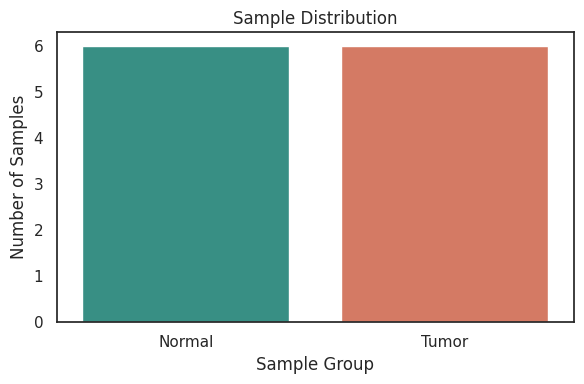

In [43]:
# 5. Visualisasi distribusi sampel

plt.figure(figsize=(6, 4))

sns.countplot(
    data=sample_info_selected,
    x="Group",
    hue="Group",
    palette={
        "Normal": "#2A9D8F",
        "Tumor": "#E76F51"
    },
    legend=False
)

plt.title("Sample Distribution")
plt.xlabel("Sample Group")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

Normal: 6 sampel.
Tumor: 6 sampel.

In [44]:
# 6. Bersihkan data ekspresi
expression_clean = expression_selected.dropna(axis=0)

expression_clean = expression_clean.loc[
    expression_clean.std(axis=1) > 0
]

print("Jumlah probe sebelum filtering:", expression_selected.shape[0])
print("Jumlah probe setelah filtering:", expression_clean.shape[0])

Jumlah probe sebelum filtering: 54675
Jumlah probe setelah filtering: 54675


Ada dua proses utama:
1. dropna(axis=0) menghapus probe yang memiliki setidaknya satu nilai kosong pada 12 sampel.
2. std(axis=1) > 0 menghapus probe yang tidak memiliki variasi ekspresi antar-sampel.
Probe dengan nilai yang sama pada seluruh sampel tidak memberikan informasi pembeda untuk analisis pola ekspresi.

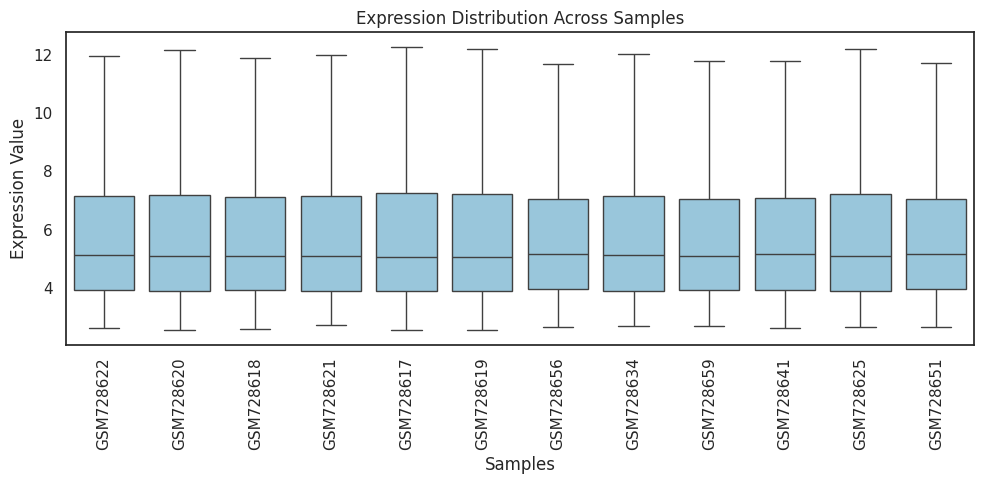

In [45]:
#7. Visualisasi distribusi ekspresi
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=expression_clean,
    color="#8ECAE6",
    showfliers=False
)

plt.title("Expression Distribution Across Samples")
plt.xlabel("Samples")
plt.ylabel("Expression Value")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Setiap kotak menggambarkan:
- Garis tengah: median ekspresi.
- Batas kotak: kuartil pertama dan ketiga.
- Whiskers: rentang data di luar kotak, sesuai aturan boxplot.
- Titik ekstrem tidak ditampilkan karena showfliers=False.
Dataset GSE29431 menggunakan data ekspresi yang telah diproses dengan metode RMA. Karena itu, kita tidak langsung melakukan normalisasi ulang tanpa alasan metodologis.

Interpretasi hasil :

Perhatikan apakah distribusi antar-sampel relatif serupa atau terdapat sampel yang memiliki median maupun rentang ekspresi sangat berbeda.
- Distribusi yang relatif serupa dapat menunjukkan konsistensi skala pengukuran antar-sampel.
- Distribusi yang sangat berbeda dapat menjadi indikasi adanya variasi teknis atau biologis yang perlu diperiksa lebih lanjut.

In [46]:
#8. Pilih 30 probe dengan variasi tertinggi
probe_variance = expression_clean.var(axis=1)

top_probes = probe_variance.sort_values(
    ascending=False
).head(30).index

top_expression = expression_clean.loc[top_probes]

print("Jumlah probe terpilih:", top_expression.shape[0])

Jumlah probe terpilih: 30


Tidak semua probe perlu ditampilkan dalam heatmap. Jika seluruh probe digunakan, visualisasi akan terlalu padat dan sulit dibaca.

Pada tahap ini, kita memilih 30 probe dengan variansi tertinggi (highest variance).

Sebelum plotting, kita melakukan Z-score standardization pada setiap probe across samples.Tujuannya adalah membandingkan pola relatif ekspresi antar sampel, bukan membandingkan besarnya ekspresi absolut antar probe.

In [47]:
#9. Normalisasi menggunakan Z-score
expression_zscore = top_expression.sub(
    top_expression.mean(axis=1),
    axis=0
).div(
    top_expression.std(axis=1),
    axis=0
)

expression_zscore = expression_zscore.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(axis=0)

print("Ukuran data Z-score:", expression_zscore.shape)

Ukuran data Z-score: (30, 12)


Z-score	Positif : 	Ekspresi relatif di atas rata-rata probe

Z-score 0 :	Ekspresi relatif mendekati rata-rata probe

Z-score Negatif :	Ekspresi relatif di bawah rata-rata probe

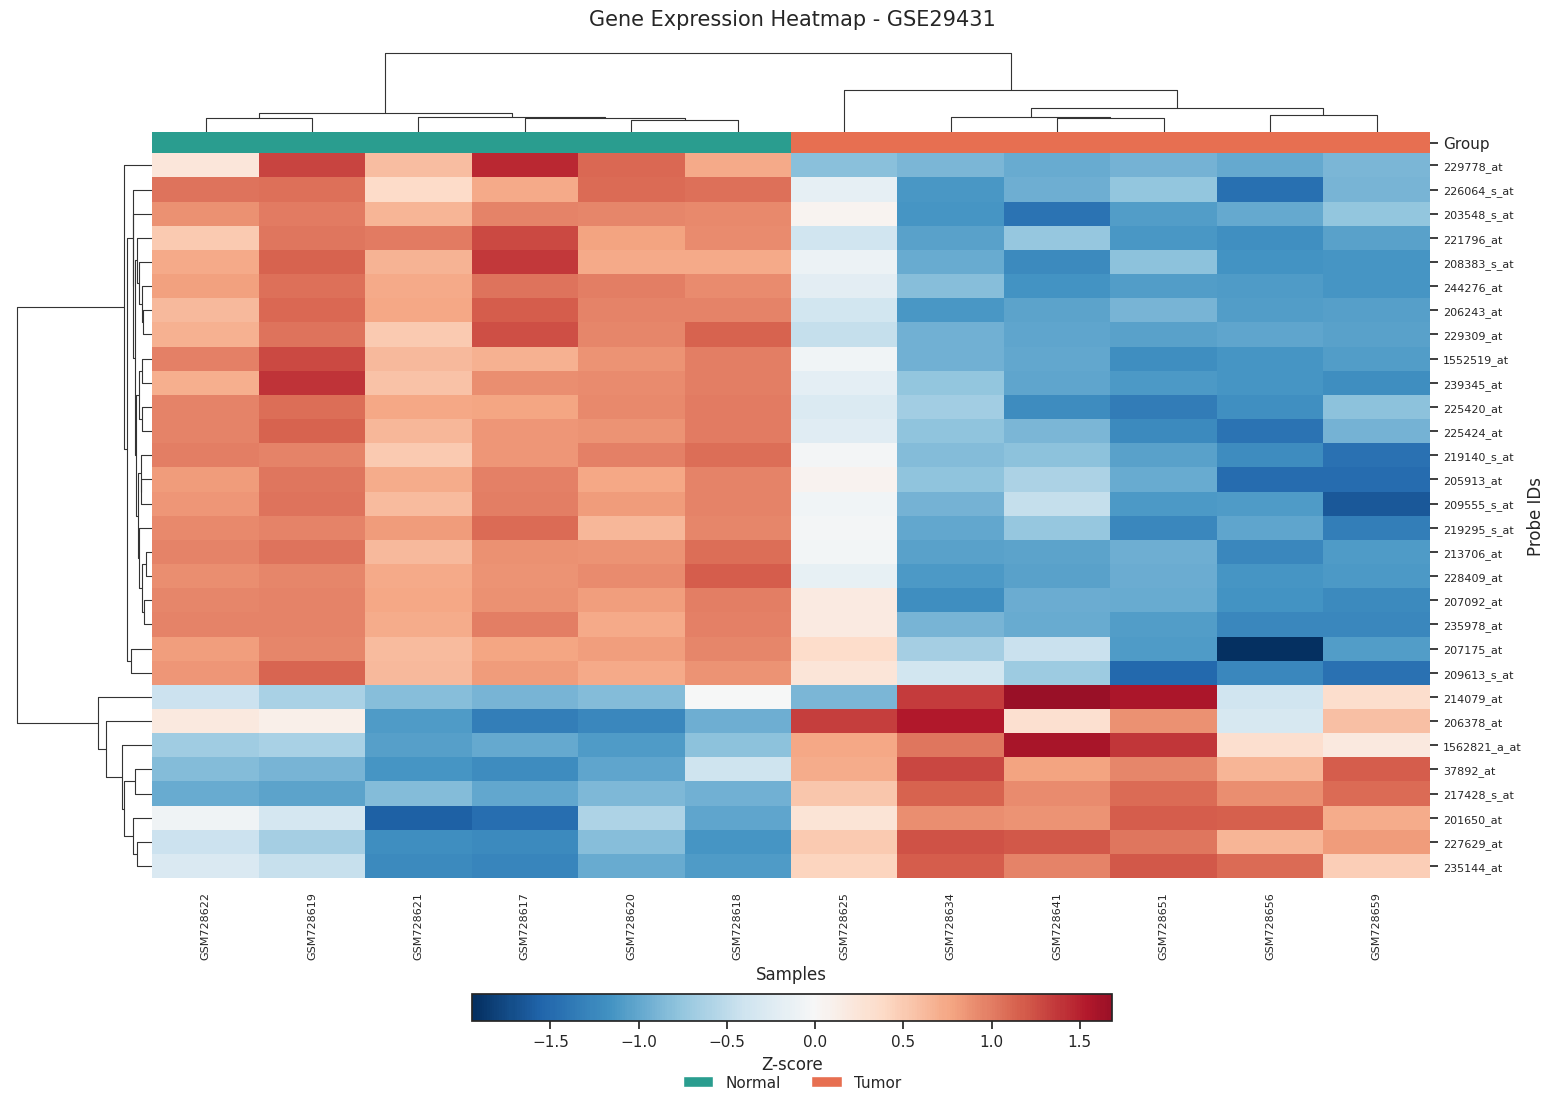

In [48]:
#10. Buat heatmap dengan hierarchical clustering
sample_colors = sample_info_selected["Group"].map({
    "Normal": "#2A9D8F",
    "Tumor": "#E76F51"
})

g = sns.clustermap(
    expression_zscore,
    cmap="RdBu_r",
    center=0,
    row_cluster=True,
    col_cluster=True,
    xticklabels=True,
    yticklabels=True,
    col_colors=sample_colors,
    figsize=(16, 11),
    linewidths=0,
    dendrogram_ratio=(0.10, 0.10),
    colors_ratio=0.025,
    cbar_pos=None,
    tree_kws={"linewidths": 0.8}
)

g.ax_heatmap.yaxis.tick_right()
g.ax_heatmap.yaxis.set_label_position("right")

g.ax_heatmap.set_xlabel("Samples")
g.ax_heatmap.set_ylabel("Probe IDs")

g.ax_heatmap.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=8
)

g.ax_heatmap.tick_params(
    axis="y",
    labelsize=8
)

g.fig.suptitle(
    "Gene Expression Heatmap - GSE29431",
    fontsize=15,
    y=1.02
)

legend_elements = [
    Patch(facecolor="#2A9D8F", label="Normal"),
    Patch(facecolor="#E76F51", label="Tumor")
]

g.fig.subplots_adjust(bottom=0.23)

# Z-score colorbar at the bottom
cbar_ax = g.fig.add_axes([0.30, 0.10, 0.40, 0.025])

g.fig.colorbar(
    g.ax_heatmap.collections[0],
    cax=cbar_ax,
    orientation="horizontal",
    label="Z-score"
)

# Sample group legend below Z-score
g.fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, 0.025),
    frameon=False
)

plt.show()

Sampel jaringan payudara normal dan kanker memiliki pola ekspresi gen yang berbeda.
- Sampel Normal cenderung mengelompok dengan sampel Normal lainnya.
- Sampel Tumor cenderung mengelompok dengan sampel Tumor lainnya.
- Warna merah dan biru menunjukkan adanya perbedaan tingkat ekspresi gen pada kedua kelompok.
Kesimpulan: Kanker payudara memiliki pola ekspresi gen yang berbeda dibandingkan jaringan normal. Perbedaan ini bisa menjadi petunjuk awal untuk mengidentifikasi gen yang berkaitan dengan kanker payudara.

Jadi, heatmap ini membantu kita melihat bahwa aktivitas gen pada jaringan normal dan kanker tidak sama.

In [49]:
#11. Simpan hasil analisis
output_folder = "GSE29431_Results"

os.makedirs(output_folder, exist_ok=True)

sample_info_selected.to_csv(
    f"{output_folder}/sample_metadata.csv"
)

expression_selected.to_csv(
    f"{output_folder}/expression_matrix.csv"
)

top_expression.to_csv(
    f"{output_folder}/top_30_probes.csv"
)

expression_zscore.to_csv(
    f"{output_folder}/expression_zscore.csv"
)

print("Semua hasil berhasil disimpan.")

Semua hasil berhasil disimpan.


In [50]:
#12. Download hasil analisis dalam ZIP
import shutil
from google.colab import files

shutil.make_archive(
    "GSE29431_Results",
    "zip",
    output_folder
)

files.download("GSE29431_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>